# Project 2: Kasese Solar Micro-Grid Dispatch Planner

## Class design and diagnostics
The two demand constraints are $3x+2y=D_1$ and $4x+y=D_2$. Determinant zero means no unique solution; a large condition number means sensitivity to errors.

In [ ]:


import sys
import subprocess
from pathlib import Path


# Identifying the project directory
root = Path.cwd()

# Checking whether src exists in the current folder
if not (root / "src").exists():
    if (root.parent / "src").exists():
        root = root.parent

# Confirm that the src folder exists
assert (root / "src").exists(), (
)

# Add the project directory to Python's search path
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

# Importing required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statistics import mean, median, variance, stdev
from scipy.linalg import solve
from timeit import repeat

# Setting random seed for reproducibility
rng = np.random.default_rng(2026)

# Importation of classes from the microgrid module
from src.microgrid import (
    MicroGrid,
    HybridMicroGrid,
    generate_demands
)

# Creating a MicroGrid object
grid = MicroGrid()

#Displaying the matrix and diagnostics
print("Matrix:")
print(grid.matrix)

print("\nDiagnostics:")
print(grid.diagnostics())


Matrix:
[[3. 2.]
 [4. 1.]]

Diagnostics:
{'determinant': -4.999999999999999, 'condition_number': 5.82842712474619}


### Creating and importing the demand dataset

In [45]:
demands=generate_demands(30,seed=2026)
df=pd.DataFrame({'day':np.arange(1,31),'D1_kWh':demands[:,0],'D2_kWh':demands[:,1]})
path=root/'data'/'microgrid_demand.csv';path.parent.mkdir(exist_ok=True)
df.to_csv(path,index=False)
df=pd.read_csv(path)
display(df.head())

,day,D1_kWh,D2_kWh
0,1,85.732677,93.900726
1,2,107.373739,117.708041
2,3,91.932862,101.234078
3,4,103.390510,118.012951
4,5,82.362689,95.033981


## 3. Interactive model

In [46]:
if not (root / "src").is_dir():
    if (root.parent / "src").is_dir():
        root = root.parent

if not (root / "src").is_dir():
    raise FileNotFoundError(
        f"Cannot find the 'src' folder. Current location: {Path.cwd()}"
    )

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.microgrid import validated_demand_input

# Interactive input
d1, d2 = validated_demand_input()

print("Interactive input result:")
print(grid.solve_day(d1, d2))

print("\nExample day:")
print(
    grid.solve_day(
        df["D1_kWh"].iloc[0],
        df["D2_kWh"].iloc[0]
    )
)


Interactive input result:
{'solar': 0.8800000000000001, 'battery': 0.0, 'raw_solar': 1.2, 'raw_battery': -0.8, 'infeasible': True, 'residual_norm': 0.8000000000000003, 'cost': 132.00000000000003}

Example day:
{'solar': 20.413755049684205, 'battery': 12.245705720731417, 'raw_solar': 20.413755049684205, 'raw_battery': 12.245705720731417, 'infeasible': False, 'residual_norm': 0.0, 'cost': 8572.630831781767}


## 4. Loop versus vectorised SciPy solver, with timings

In [47]:
d=df[['D1_kWh','D2_kWh']].to_numpy()
loop=np.array([solve(grid.matrix,row) for row in d])
vector=grid.solve_many(d)
assert np.allclose(loop,vector)
loop_time=min(repeat(lambda:[solve(grid.matrix,row) for row in d],number=200,repeat=5))
vec_time=min(repeat(lambda:grid.solve_many(d),number=200,repeat=5))
print('Loop seconds per 200 runs:',loop_time,'Vectorised:',vec_time,'Speedup:',loop_time/vec_time)

Loop seconds per 200 runs: 0.1425182999810204 Vectorised: 0.01705470005981624 Speedup: 8.356540981733101


## 5. Feasibility handling and costs

In [ ]:
dispatch=pd.DataFrame([grid.solve_day(*row) for row in d]); result=pd.concat([df,dispatch],axis=1)
print('Infeasible days are:',result.infeasible.sum())
print('Deliberately infeasible example:',grid.solve_day(10,100))
print('Monthly energy cost (UGX):',round(result.cost.sum(),2))
display(result[['day','solar','battery','cost','infeasible','residual_norm']].head())

Infeasible days: 0
Deliberately infeasible example: {'solar': 17.2, 'battery': 0.0, 'raw_solar': 38.0, 'raw_battery': -52.0, 'infeasible': True, 'residual_norm': 51.99999999999999, 'cost': 2580.0}
Monthly energy cost (UGX): 272341.65


,day,solar,battery,cost,infeasible,residual_norm
0,1,20.413755,12.245706,8572.630832,False,0.0
1,2,25.608468,15.274167,10714.645371,False,0.0
2,3,22.107059,12.805843,9078.688025,False,0.0
3,4,26.527078,11.904637,9336.148605,False,0.0
4,5,21.541055,8.869763,7222.551318,False,0.0


## 6. Descriptive statistics and chart

solar mean 22.09810305953279 variance 10.145275879677452 SD 3.1851649689894326
battery mean 12.807421470617797 variance 4.835545469189891 SD 2.1989873735858265
More volatile (absolute SD): solar


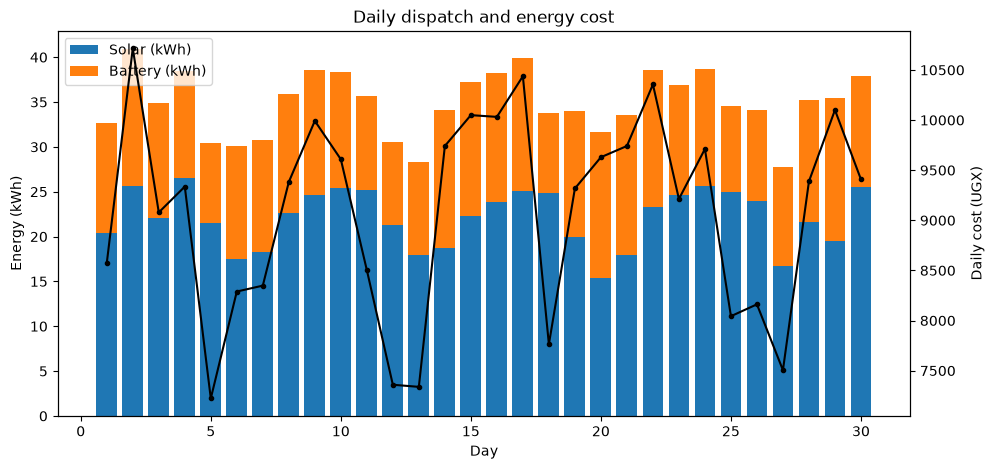

In [49]:
for source in ['solar','battery']:
 x=result[source].tolist();print(source,'mean',mean(x),'variance',variance(x),'SD',stdev(x))
print('More volatile (absolute SD):',max(['solar','battery'],key=lambda k:stdev(result[k].tolist())))
fig,ax=plt.subplots(figsize=(11,5))
ax.bar(result.day,result.solar,label='Solar (kWh)');ax.bar(result.day,result.battery,bottom=result.solar,label='Battery (kWh)')
ax.set(xlabel='Day',ylabel='Energy (kWh)',title='Daily dispatch and energy cost');ax.legend(loc='upper left')
ax2=ax.twinx();ax2.plot(result.day,result.cost,color='black',marker='.',label='Cost');ax2.set_ylabel('Daily cost (UGX)');plt.show()

## 7. Extension: hybrid source and Monte Carlo sensitivity

In [50]:
hybrid=HybridMicroGrid();print('Hybrid example:',hybrid.solve_hybrid(np.array([100.,110.,70.])))
perturbed=d[0]*(1+rng.uniform(-.05,.05,size=(1000,2)))
sensitivity=grid.solve_many(perturbed)
print('Sensitivity SD (solar, battery):',sensitivity.std(axis=0))
print('Condition number:',grid.diagnostics()['condition_number'])

Hybrid example: {'sources': array([17.14285714, 18.57142857, 11.42857143]), 'raw_feasible': True, 'cost': 20071.428571428572, 'residual_norm': 0.0}
Sensitivity SD (solar, battery): [1.18820412 2.56613526]
Condition number: 5.82842712474619


## Findings & Limitations
In some cases, the model gave negative energy values, which would not make sense in a real-life situation because we cannot supply negative amounts of electricity. I used non-negative least squares (NNLS) to correct this, although the results still showed some gaps between the energy required and what the system could provide. One limitation of this project is that I used simulated data rather than actual electricity demand from a health centre. The model also assumes that solar and battery energy follow fixed relationships, which may not always be the case in practice. For example, changes in weather, battery storage limits and energy losses can affect how much electricity is available at any given time.